# Models for several counting sites

Can the forecast model of the Warendorfer Straße (notebook 02) forecast other counting sites too,
and is one **global model** for all sites better than **one model per site**?

This notebook uses the 9 sites with data since 2020 or earlier, so that every site has at least
three years of training data before the first test quarter (2023). It compares, with the same
time-based cross-validation as notebook 02:

1. **Naive baseline** per site: same weekday one week earlier
2. **Holiday baseline** per site: naive baseline times a factor per kind of special day off
3. **LightGBM per site**: the model of notebook 02, trained separately for each site
4. **Global LightGBM**: one model for all sites, with counts and lags divided by the median count
   of each site, and the site as a categorical feature

Requires the raw data in `data/raw` (the daily job or `python -m radmuenster.forecast` downloads it).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from radmuenster.data import DEFAULT_SITE, load_intervals, to_daily
from radmuenster.evaluation import cross_validate, summarize, time_series_folds
from radmuenster.explore import PALETTE
from radmuenster.features import PERIOD_STARTS
from radmuenster.models import holiday_baseline, lightgbm, naive_baseline
from radmuenster.multi_site import LONG_HISTORY_SITES, global_lightgbm, per_site, site_counts, sites_table
from radmuenster.sites import load_all_sites
from radmuenster.weather import load_weather

RAW = Path("..") / "data" / "raw"
all_sites, failed = load_all_sites(cache_dir=RAW)
assert not failed, failed
weather = load_weather(cache_dir=RAW / "weather")

# The Warendorfer Straße keeps its own daily counts (to_daily): only they know
# the direction faults and the known faults. The other sites use the flags of sites.py.
counts = {
    site.name: to_daily(load_intervals(DEFAULT_SITE, cache_dir=RAW)) if site.id == DEFAULT_SITE
    else site_counts(all_sites[all_sites["site_id"] == site.id])
    for site in LONG_HISTORY_SITES
}
SITE_NAMES = list(counts)
print(f"{len(SITE_NAMES)} sites: {', '.join(SITE_NAMES)}")

9 sites: Warendorfer Straße, Hammer Straße, Weseler Straße, Hüfferstraße, Gartenstraße, Neutor, Promenade (nördl. Salzstraße), Kanalpromenade, Abschnitt 5, Hafenstraße


## 1. The sites

Days with a flag (outage, partial day, dead channel, fault status) are left out of training and
evaluation, as at the Warendorfer Straße.

In [2]:
overview = pd.DataFrame({
    name: {
        "first day": daily.index.min().strftime("%Y-%m-%d"),
        "days": len(daily),
        "usable days": f"{daily['complete'].mean():.0%}",
        "median per day": daily.loc[daily["complete"], "count"].median(),
    }
    for name, daily in counts.items()
}).T
overview.sort_values("median per day", ascending=False)

,first day,days,usable days,median per day
Promenade (nördl. Salzstraße),2019-01-01,2848,96%,14568.0
Neutor,2019-01-01,2848,92%,10222.0
Hammer Straße,2019-01-01,2848,98%,7549.5
Hafenstraße,2020-01-01,2483,97%,6899.0
Warendorfer Straße,2019-01-01,2798,90%,6437.0
Hüfferstraße,2019-01-01,2848,97%,5417.0
Weseler Straße,2019-01-01,2848,96%,2986.5
Gartenstraße,2019-01-01,2848,96%,2762.0
"Kanalpromenade, Abschnitt 5",2019-07-09,2659,96%,960.0


The sites differ more than tenfold in size: from a median of about 1,000 trips per day on the
Kanalpromenade to almost 15,000 on the Promenade. A global model has to deal with that.

## 2. Measurement jumps?

At the Warendorfer Straße, the counting site changed twice (June 2024, October 2025); the
model gets the measurement period as a feature. For the other sites no such jumps are known,
and without labelled directions the inbound-share check of the Warendorfer Straße does not work.
Instead: the **share of each site in the total of all nine sites**, on days when all nine have
usable data. Weather, holidays and the season affect all sites alike and cancel out; a counting
site that suddenly counts more or less shows up as a lasting step in its share.

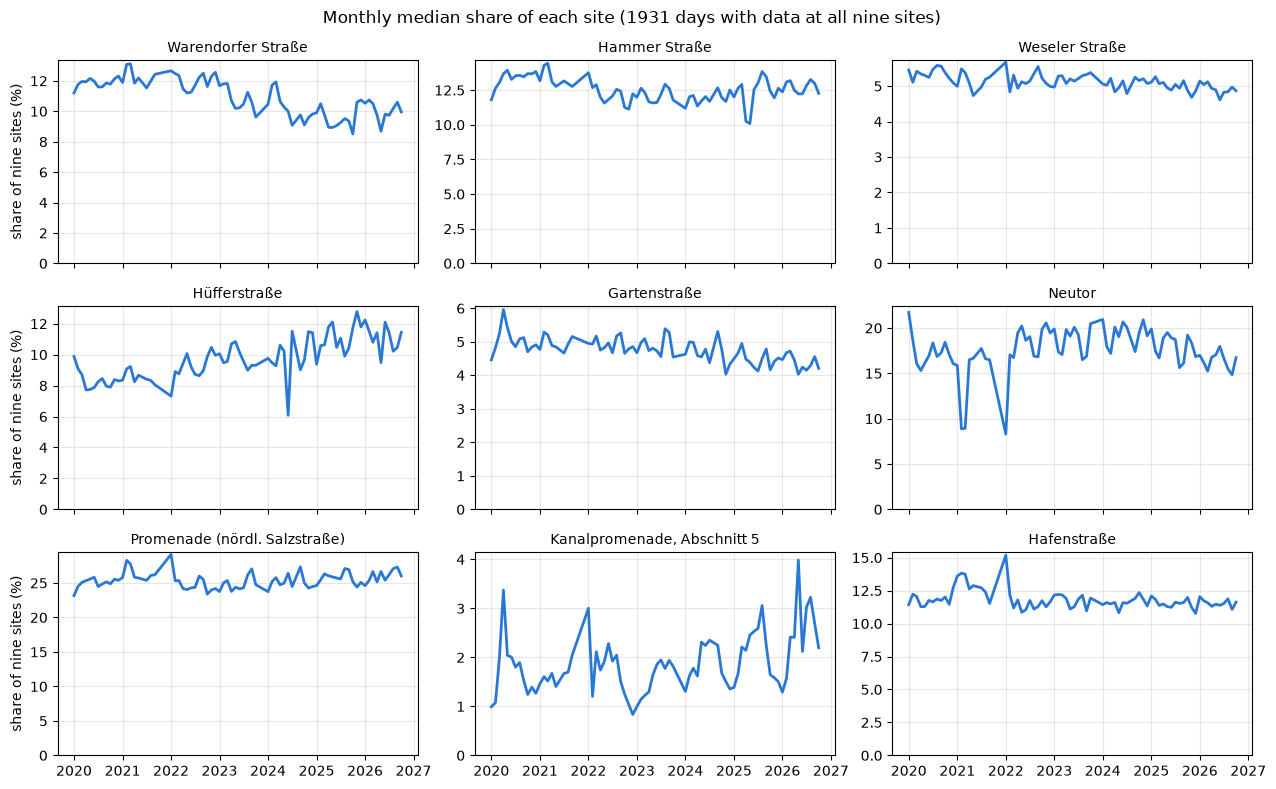

In [3]:
complete_counts = pd.DataFrame({name: daily["count"].where(daily["complete"]) for name, daily in counts.items()})
complete_counts = complete_counts.dropna()
share = complete_counts.div(complete_counts.sum(axis=1), axis=0)
monthly_share = share.groupby(share.index.to_period("M")).median()
monthly_share.index = monthly_share.index.to_timestamp()

fig, axes = plt.subplots(3, 3, figsize=(13, 8), sharex=True)
for ax, name in zip(axes.flat, SITE_NAMES):
    ax.plot(monthly_share.index, monthly_share[name] * 100, color=PALETTE["light"][0], lw=2)
    ax.set_title(name, fontsize=10)
    ax.set_ylim(0, None)
    ax.grid(alpha=0.3)
for ax in axes[:, 0]:
    ax.set_ylabel("share of nine sites (%)")
fig.suptitle(f"Monthly median share of each site ({len(complete_counts)} days with data at all nine sites)")
fig.tight_layout()
plt.show()

Apart from the known changes at the Warendorfer Straße, no site shows a sharp, lasting step.
What the shares do show:

- **Short dips are outages that the flags miss.** The Neutor drops to about half its share in early
  and in late 2021 (an outage of 2021 that the flags only partly catch), the Hüfferstraße
  in mid-2024 and the Hammer Straße in early 2025 for a month or two. Because a share is relative
  to all nine sites, the other sites rise at the same time (e.g. the Hafenstraße and the Promenade
  in early 2021 and early 2022). These days stay in the training data; the 2021 dips lie before
  the first test quarter.
- **The Kanalpromenade** swings with the season (higher in summer, probably a leisure route) and
  grows over the years.
- **The Hüfferstraße** grows from about 8 % to about 11 % since 2021, gradually and not in one
  step, which looks more like traffic than like a new counter.

So no measurement periods are added for any of the other eight sites.

## 3. Comparison

The same folds for all models: each quarter from 2023 on is a test period, trained on all days
before it. MAE is in trips per day, WAPE is the sum of errors divided by the sum of actual counts,
which makes the sites comparable.

In [4]:
table = sites_table(counts, weather, period_starts={"Warendorfer Straße": PERIOD_STARTS})
print(f"{len(table)} rows (site days), {table.shape[1] - 2} features")

MODELS = {
    "naive baseline": per_site(naive_baseline),
    "holiday baseline": per_site(holiday_baseline),
    "LightGBM per site": per_site(lightgbm),
    "global LightGBM": global_lightgbm,
}
predictions = {name: cross_validate(model, table, keep=("site",)) for name, model in MODELS.items()}

overall = pd.concat({name: summarize(p).iloc[0] for name, p in predictions.items()}, axis=1).T
overall["n_days"] = overall["n_days"].astype(int)
overall.style.format({"mae": "{:.0f}", "wape": "{:.1%}", "mape": "{:.1%}", "nrmse": "{:.1%}"})

23871 rows (site days), 25 features


,n_days,mae,wape,mape,nrmse
naive baseline,11803,1160,17.9%,32.1%,29.6%
holiday baseline,11803,1050,16.2%,26.1%,25.1%
LightGBM per site,11803,582,9.0%,13.1%,13.8%
global LightGBM,11803,591,9.1%,14.3%,14.1%


In [5]:
by_site = {name: summarize(p, by="site") for name, p in predictions.items()}
wape = pd.DataFrame({name: s["wape"] for name, s in by_site.items()}).sort_values("LightGBM per site")
mae = pd.DataFrame({name: s["mae"] for name, s in by_site.items()}).loc[wape.index]
pd.concat({"MAE (trips)": mae.round(0), "WAPE (%)": (wape * 100).round(1)}, axis=1)

MAE (trips)                   \
                              naive baseline holiday baseline   
site                                                            
Hafenstraße                            904.0            836.0   
Promenade (nördl. Salzstraße)         2477.0           2231.0   
Gartenstraße                           465.0            412.0   
Weseler Straße                         550.0            502.0   
Warendorfer Straße                     957.0            847.0   
Neutor                                1962.0           1785.0   
Hammer Straße                         1309.0           1164.0   
Hüfferstraße                          1397.0           1248.0   
Kanalpromenade, Abschnitt 5            421.0            424.0   

                                                                 \
                              LightGBM per site global LightGBM   
site                                                              
Hafenstraße                               450.0           476.0   
Promenade (nördl. Salzstraße)            1073.0          1103.0   
Gartenstraße                              222.0           221.0   
Weseler Straße                            247.0           256.0   
Warendorfer Straße                        524.0           501.0   
Neutor                                    948.0          1021.0   
Hammer Straße                             727.0           644.0   
Hüfferstraße                              827.0           876.0   
Kanalpromenade, Abschnitt 5               218.0           221.0   

                                    WAPE (%)                   \
                              naive baseline holiday baseline   
site                                                            
Hafenstraße                             13.3             12.3   
Promenade (nördl. Salzstraße)           16.7             15.1   
Gartenstraße                            17.3             15.3   
Weseler Straße                          18.8             17.2   
Warendorfer Straße                      16.0             14.2   
Neutor                                  18.5             16.8   
Hammer Straße                           18.0             16.0   
Hüfferstraße                            22.7             20.3   
Kanalpromenade, Abschnitt 5             33.6             33.8   

                                                                 
                              LightGBM per site global LightGBM  
site                                                             
Hafenstraße                                 6.6             7.0  
Promenade (nördl. Salzstraße)               7.2             7.4  
Gartenstraße                                8.3             8.2  
Weseler Straße                              8.4             8.8  
Warendorfer Straße                          8.8             8.4  
Neutor                                      8.9             9.6  
Hammer Straße                              10.0             8.9  
Hüfferstraße                               13.4            14.2  
Kanalpromenade, Abschnitt 5                17.4            17.6

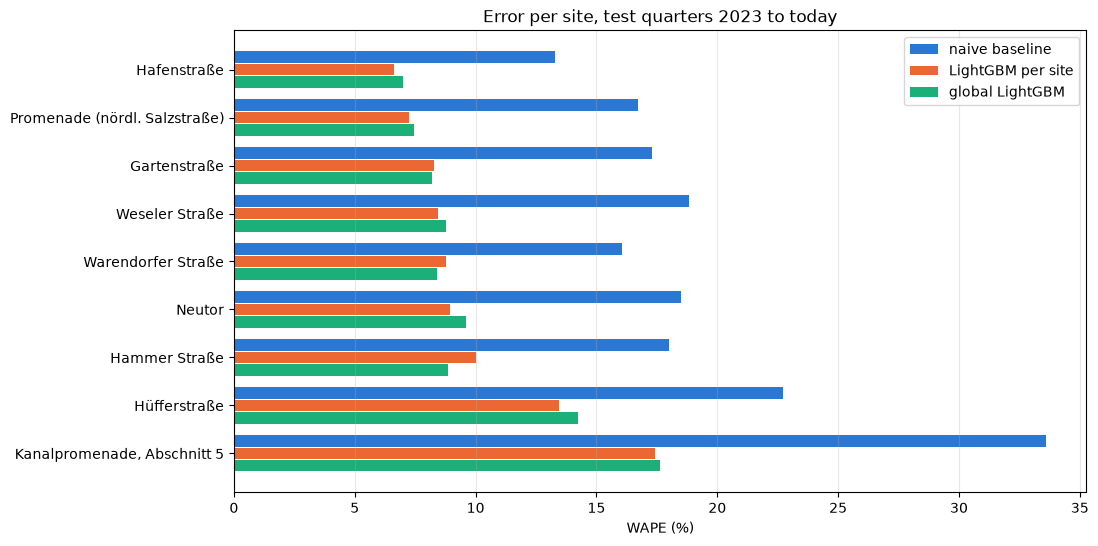

In [6]:
# The same colour per model as in the table order; the holiday baseline is left out
# of the plot, it is close to the naive baseline
SHOWN = ["naive baseline", "LightGBM per site", "global LightGBM"]
COLORS = dict(zip(SHOWN, PALETTE["light"]))

fig, ax = plt.subplots(figsize=(11, 6))
height = 0.26
y = np.arange(len(wape))
for i, name in enumerate(SHOWN):
    ax.barh(y + (i - 1) * height, wape[name] * 100, height=height * 0.9, color=COLORS[name], label=name)
ax.set_yticks(y, wape.index)
ax.invert_yaxis()
ax.set_xlabel("WAPE (%)")
ax.set_title("Error per site, test quarters 2023 to today")
ax.legend(loc="upper right")
ax.grid(axis="x", alpha=0.3)
plt.show()

LightGBM roughly halves the error of the naive baseline at every site. The sites differ a lot,
though: the Promenade and the Hafenstraße are forecast best, the Kanalpromenade and the
Hüfferstraße worst. The Kanalpromenade is small and swings with the season, the Hüfferstraße
grows (section 2): a level that keeps moving is harder to forecast.

The model of the Warendorfer Straße is the same as in notebook 02; its error here is close to
the published 529 trips, with a few more test days.

## 4. Global model or one model per site?

In [7]:
diff = pd.DataFrame({
    "WAPE per site (%)": wape["LightGBM per site"] * 100,
    "WAPE global (%)": wape["global LightGBM"] * 100,
})
diff["global minus per site (points)"] = diff["WAPE global (%)"] - diff["WAPE per site (%)"]
diff.round(1).sort_values("global minus per site (points)")

,WAPE per site (%),WAPE global (%),global minus per site (points)
site,,,
Hammer Straße,10.0,8.9,-1.1
Warendorfer Straße,8.8,8.4,-0.4
Gartenstraße,8.3,8.2,-0.1
Promenade (nördl. Salzstraße),7.2,7.4,0.2
"Kanalpromenade, Abschnitt 5",17.4,17.6,0.2
Weseler Straße,8.4,8.8,0.3
Hafenstraße,6.6,7.0,0.4
Neutor,8.9,9.6,0.7
Hüfferstraße,13.4,14.2,0.8


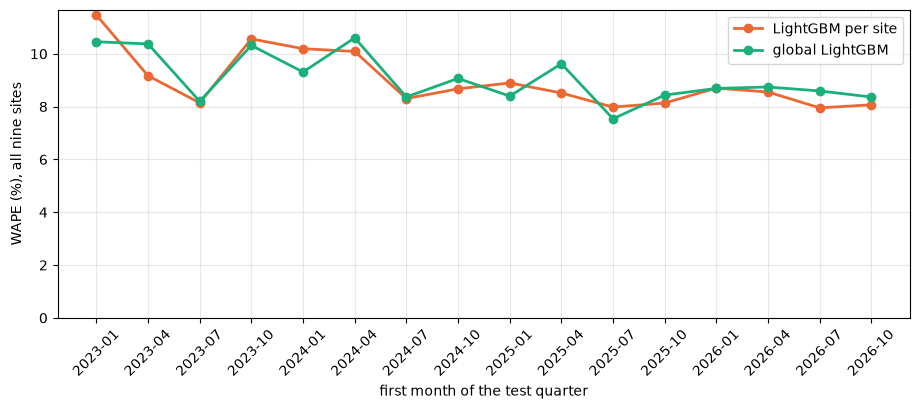

In [8]:
folds = [table.index[test].min() for _, test in time_series_folds(table.index)]
by_fold = pd.DataFrame({name: summarize(predictions[name], by="fold")["wape"] * 100 for name in SHOWN[1:]})
by_fold.index = [f"{start:%Y-%m}" for start in folds]

fig, ax = plt.subplots(figsize=(11, 4))
for name in SHOWN[1:]:
    ax.plot(by_fold.index, by_fold[name], marker="o", lw=2, color=COLORS[name], label=name)
ax.set_ylabel("WAPE (%), all nine sites")
ax.set_xlabel("first month of the test quarter")
ax.set_ylim(0, None)
ax.tick_params(axis="x", rotation=45)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

Over all nine sites the two approaches are about equally good: the global model is better at
some sites and worse at others, by about one percentage point at most, and neither wins every
quarter. With four or more years of history, each site has enough data of its own; pooling the
sites does not add much.

## 5. Conclusions

- **Forecasts for other sites work** with the same features and model: WAPE between about 7 %
  and 17 %, half the error of the naive baseline everywhere.
- **Global or per site makes no real difference** for sites with a long history. The global model
  is simpler to run (one model, about four times faster to train here), which matters for the
  daily job.
- The global model's real advantage should show at the **13 sites with data only since
  2023/2024**: too little history for a model of their own, but the patterns are the same as
  at the long sites. That is the next test, before deciding whether forecasts for more sites go
  into the daily job (step 8b).
- **No measurement periods** were found for the other eight sites (section 2). A jump would only
  show as a growing error; the bias check of the monitoring would catch it if the sites get
  daily forecasts.